In [1]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import pandas as pd


from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Conv2D, Dense, Dropout, Flatten, MaxPooling2D, BatchNormalization, InputLayer, Reshape
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2

import warnings
warnings.filterwarnings('ignore')

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/muratkokludataset/rice-image-dataset


In [3]:

import os

print(os.listdir(path))

['Rice_Image_Dataset']


In [4]:
data_path = path + "/Rice_Image_Dataset"

print(os.listdir(data_path))

['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag', 'Rice_Citation_Request.txt']


In [5]:
labels = ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']

img_path = data_path + '/'

In [6]:
img_list=[]
label_list=[]
for label in labels:
    for img_file in os.listdir(img_path+label):
        img_list.append(img_path+label+'/'+img_file)
        label_list.append(label)

In [7]:
df = pd.DataFrame({
    'img': img_list,
    'label': label_list
})

In [8]:
df.head()

,img,label
0,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
1,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
2,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
3,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio
4,/kaggle/input/datasets/muratkokludataset/rice-...,Arborio


In [9]:
d={'Arborio':0, 'Basmati':1, 'Ipsala':2, 'Jasmine':3, 'Karacadag':4}
df['encode_label']=df['label'].map(d) 

In [10]:
df.tail()

,img,label,encode_label
74995,/kaggle/input/datasets/muratkokludataset/rice-...,Karacadag,4
74996,/kaggle/input/datasets/muratkokludataset/rice-...,Karacadag,4
74997,/kaggle/input/datasets/muratkokludataset/rice-...,Karacadag,4
74998,/kaggle/input/datasets/muratkokludataset/rice-...,Karacadag,4
74999,/kaggle/input/datasets/muratkokludataset/rice-...,Karacadag,4


In [11]:
from tqdm import tqdm
x=[]
for img in tqdm(df['img']):
    img = cv2.imread(str(img))
    img = cv2.resize(img,(64,64))
    img = (img/255.0).astype(np.float32)
    x.append(img)

100%|██████████| 75000/75000 [48:44<00:00, 25.65it/s]  


In [12]:
  x=np.array(x,dtype=np.float32)

In [13]:
y=df['encode_label']

In [15]:
df.columns

Index(['img', 'label', 'encode_label'], dtype='object')

In [16]:
x_train,x_test,y_train,y_test=train_test_split(x,y, random_state=42, test_size=0.20)

In [17]:
y_train = np.array(y_train, dtype=np.int32)
y_test = np.array(y_test, dtype=np.int32)

In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.regularizers import l2

model = Sequential()

model.add(Conv2D(32, (3,3), activation='relu',
                 input_shape=(64,64,3),
                 kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(64, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))
model.add(MaxPooling2D((2,2)))
model.add(Conv2D(128, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))
model.add(Conv2D(128, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))

model.add(MaxPooling2D((2,2)))


model.add(Conv2D(256, (3,3), activation='relu',
                 kernel_regularizer=l2(0.001)))


model.add(Flatten())

model.add(Dense(256, activation='relu',
                kernel_regularizer=l2(0.001)))

model.add(Dropout(0.5))


model.add(Dense(5, activation='softmax'))

In [19]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,127,365 (4.30 MB)

 Trainable params: 1,127,365 (4.30 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history_cnn=model.fit(x_train,y_train,validation_data=(x_test,y_test), batch_size=64, epochs=20,verbose=1)

Epoch 1/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 35s 24ms/step - accuracy: 0.9295 - loss: 0.4228 - val_accuracy: 0.9697 - val_loss: 0.2170
Epoch 2/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9635 - loss: 0.2116 - val_accuracy: 0.9685 - val_loss: 0.1778
Epoch 3/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9694 - loss: 0.1746 - val_accuracy: 0.9753 - val_loss: 0.1474
Epoch 4/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9744 - loss: 0.1486 - val_accuracy: 0.9753 - val_loss: 0.1354
Epoch 5/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9785 - loss: 0.1306 - val_accuracy: 0.9853 - val_loss: 0.1078
Epoch 6/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9826 - loss: 0.1149 - val_accuracy: 0.9855 - val_loss: 0.1057
Epoch 7/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9829 - loss: 0.1098 - val_accuracy: 0.9866 - val_loss: 0.0935
Epoch 8/20
938/938 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.9841 - loss: 0.1023 - 

In [22]:
model.save('riceModel.keras')

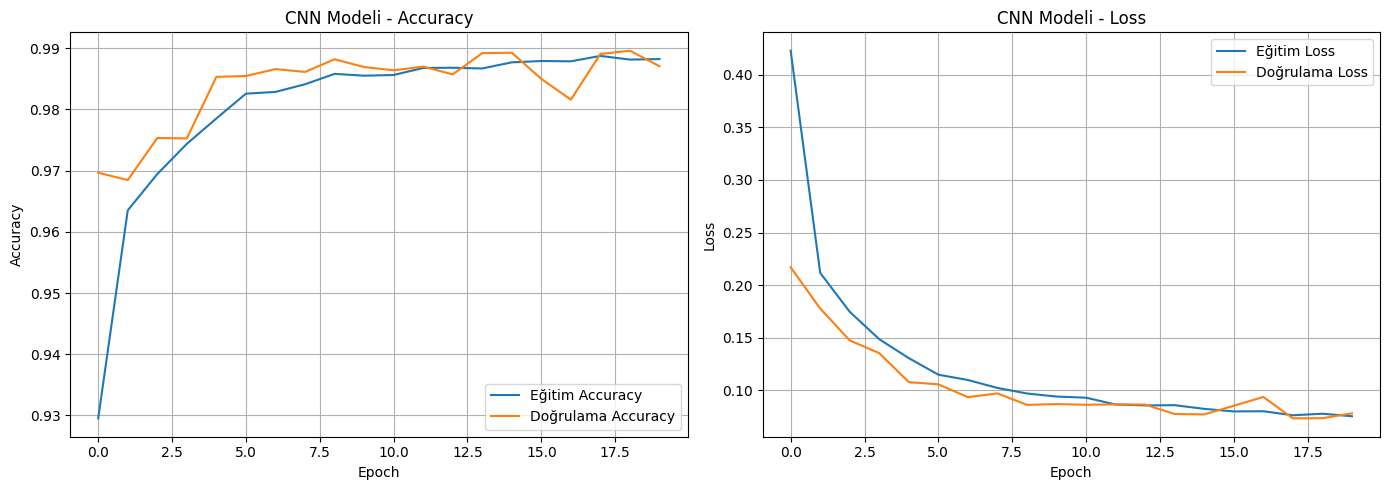

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy grafiği
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['accuracy'], label='Eğitim Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Doğrulama Accuracy')
plt.title('CNN Modeli - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss grafiği
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['loss'], label='Eğitim Loss')
plt.plot(history_cnn.history['val_loss'], label='Doğrulama Loss')
plt.title('CNN Modeli - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('CNN_Grafikleri.png', dpi=300, bbox_inches='tight')
plt.show()

In [24]:
# Transfer Learning

In [26]:
from tensorflow.keras.applications import VGG16, ResNet50

In [30]:
data_dir=path
img_width,img_height=64,64
train_datagen=ImageDataGenerator(rescale=1/255, validation_split=.20)

train_datagenerator=train_datagen.flow_from_directory(directory=data_dir,target_size=(img_width, img_height),
                                class_mode='categorical', subset='training')
test_datagen=ImageDataGenerator(rescale=1/255, validation_split=.20)

test_datagenerator=train_datagen.flow_from_directory(directory=data_dir, target_size=(img_width,img_height),class_mode='categorical', subset='validation')

base_model=VGG16(weights='imagenet', input_shape=(img_width,img_height,3), include_top=False)
#base_model=ResNet50(weights='imagenet', input_shape=(img_width,img_height,3), include_top=False) << bunu da deneyebiliridk

model=Sequential()
model.add(base_model)
for layer in base_model.layers:
    layer.trainable=False
model.add(Flatten())
model.add(Dense(1024, activation='relu'))
model.add(Dense(5, activation='softmax'))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

Found 60000 images belonging to 1 classes.
Found 15000 images belonging to 1 classes.


In [31]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 2, 2, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,817,989 (64.16 MB)

 Trainable params: 2,103,301 (8.02 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [33]:
history=model.fit(train_datagenerator,epochs=30,batch_size=64,validation_data=test_datagenerator)

Epoch 1/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 97s 52ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 95s 51ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 103s 55ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 103s 55ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 99s 53ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 102s 55ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/30
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 103s 55ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/30
1875/

In [34]:
model.save('riceModelTL.keras')

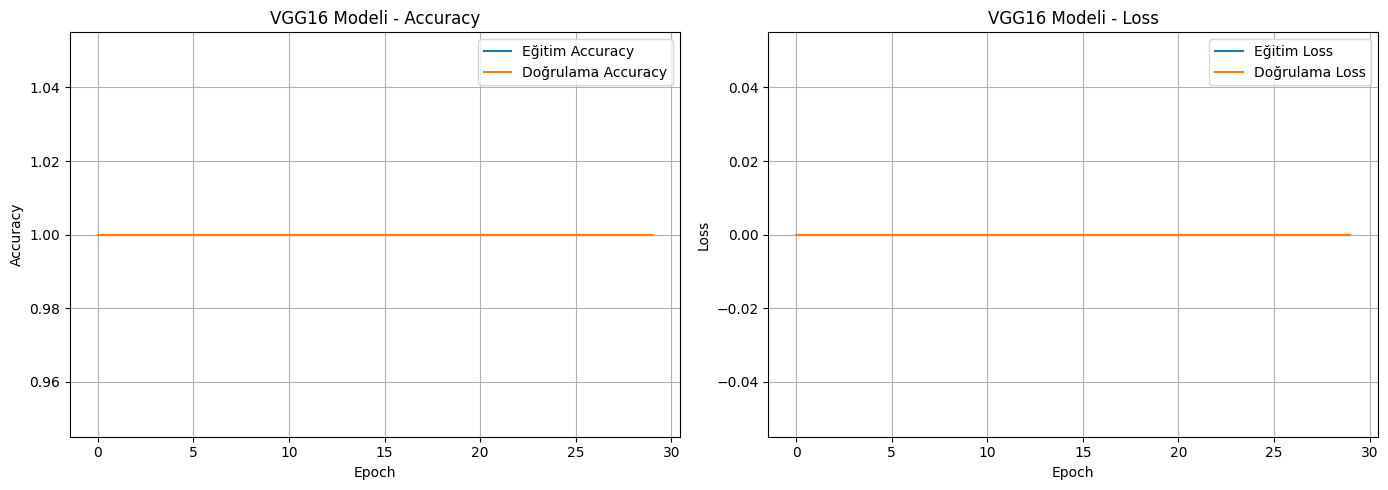

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy grafiği
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Eğitim Accuracy')
plt.plot(history.history['val_accuracy'], label='Doğrulama Accuracy')
plt.title('VGG16 Modeli - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss grafiği
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Eğitim Loss')
plt.plot(history.history['val_loss'], label='Doğrulama Loss')
plt.title('VGG16 Modeli - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('VGG16_Grafikleri.png', dpi=300, bbox_inches='tight')
plt.show()

In [36]:
print(labels)
print(d)

['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
{'Arborio': 0, 'Basmati': 1, 'Ipsala': 2, 'Jasmine': 3, 'Karacadag': 4}
